In [ ]:
import numpy as np

In [12]:
import gzip

# Load MNIST dataset
def extract_images(filename):
    with gzip.open(filename, 'rb') as f:
        magic, num, rows, cols = np.frombuffer(f.read(16), dtype=np.uint32, count=4).byteswap()
        images = np.frombuffer(f.read(), dtype=np.uint8).reshape(num, rows, cols)
    return images

def extract_labels(filename):
    with gzip.open(filename, 'rb') as f:
        magic, num = np.frombuffer(f.read(8), dtype=np.uint32, count=2).byteswap()
        labels = np.frombuffer(f.read(), dtype=np.uint8)
    return labels

train_images = extract_images("./MNISTdata/train-images-idx3-ubyte.gz")
train_labels = extract_labels("./MNISTdata/train-labels-idx1-ubyte.gz")
test_images = extract_images("./MNISTdata/t10k-images-idx3-ubyte.gz")
test_labels = extract_labels("./MNISTdata/t10k-labels-idx1-ubyte.gz")

# Implement Backpropagation

In [ ]:
import numpy as np

class NeuralNetwork:
    def __init__(self, input_size=784, hidden_layers=[512, 512], output_size=10):
        self.input_size = input_size
        self.hidden_layers = hidden_layers
        self.output_size = output_size
        self.weights = []
        self.biases = []
        self.gradientsWeights = []
        self.gradientsBiases = []
        self.iterations = 0

        # Input to Hidden Layers Network
        # np.random.seed(0)
        self.weights.append(0.01 * np.random.randn(input_size, hidden_layers[0]))
        self.biases.append(np.zeros((1, hidden_layers[0])))

        # Hidden Layers Network
        for i in range(len(hidden_layers)-1):
            # np.random.seed(0)
            self.weights.append(0.01 * np.random.randn(hidden_layers[i], hidden_layers[i+1]))
            self.biases.append(np.zeros((1, hidden_layers[i+1])))

        # Hidden Layers Network to Output
        # np.random.seed(0)
        self.weights.append(0.01 * np.random.randn(hidden_layers[len(hidden_layers)-1], output_size))
        self.biases.append(np.zeros((1, output_size)))

    def forward(self, inputs):
        self.outputs = [inputs]
        self.outputsTesting = ["inputs"]

        for i in range(len(self.weights)):
            # Dot Product to
            self.outputs.append(np.dot(self.outputs[-1], self.weights[i]) + self.biases[i])
            self.outputsTesting.append("dense")

            # Activation Functions (ReLU + SoftMax)
            if i == len(self.weights)-1:
                finalOutput = np.exp(self.outputs[-1] - np.max(self.outputs[-1], axis=1, keepdims=True))
                finalOutput = finalOutput / np.sum(finalOutput, axis=1, keepdims=True)
                self.outputs.append(finalOutput)
                self.outputsTesting.append("softmax")
            else:
                self.outputs.append(np.maximum(0, self.outputs[-1]))
                self.outputsTesting.append("relu")

        return self.outputs[-1]

    def backwards(self, y_true):
        # Softmax + LossCategoricalEntropy
        #       -> Still don't fully understand the derivation for this (working on it)
        #       -> I roughly understand the following code but it was extracted from the nnfs textbook
        #       -> nnfs textBook -> https://nnfs.io/

        # Number of samples
        samples = len(self.outputs[-1])

        # If labels are one-hot encoded,
        # turn them into discrete values
        if len(y_true.shape) == 2:
            print("Chaning to Discrete Values")
            y_true = np.argmax(y_true, axis=1)

        # Copy so we can safely modify
        dSoftMaxCrossEntropy = self.outputs[-1].copy()
        # Calculate gradient
        dSoftMaxCrossEntropy[range(samples), y_true] -= 1
        # Normalize gradient
        dSoftMaxCrossEntropy = dSoftMaxCrossEntropy / samples
        # print(dSoftMaxCrossEntropy)

        # print(dSoftMaxCrossEntropy)
        # Calculate gradients -> Calcualte derivative of weights, biases, and inputs (to continue to backpropagate)
        dInputs = np.dot(dSoftMaxCrossEntropy.copy(), self.weights[-1].T)

        dWeights = np.dot(self.outputs[-3].T, dSoftMaxCrossEntropy.copy())
        dBiases = np.sum(dSoftMaxCrossEntropy.copy(), axis=0, keepdims=True)
        self.gradientsWeights = [dWeights] + self.gradientsWeights
        self.gradientsBiases = [dBiases] + self.gradientsBiases


        i = -3
        j = -1
        for _ in range(len(self.hidden_layers)):
            i -= 1
            j -= 1

            # ReLU activation Function
            dInputsReLU = dInputs.copy()
            dInputsReLU[self.outputs[i] <= 0] = 0

            i -= 1
            dInputs = np.dot(dInputsReLU, self.weights[j].T)
            dWeights = np.dot(self.outputs[i].T, dInputsReLU)
            dBiases = np.sum(dInputsReLU, axis=0, keepdims=True)
            self.gradientsWeights = [dWeights] + self.gradientsWeights
            self.gradientsBiases = [dBiases] + self.gradientsBiases

        # print("dense1.dweights")
        # print(dWeights)
        # print(dWeights.shape)
        # print("dense1.dbiases")
        # print(dBiases)
        # print(dBiases.shape)

    def updateParams(self, lr=0.05, decay=1e-7):
        lr = lr * (1. / (1. + decay * self.iterations))

        for i in range(len(self.weights)-1):
            if i != len(self.weights)-1:
                assert self.weights[i].shape == self.gradientsWeights[i].shape
                self.weights[i] += -lr*self.gradientsWeights[i]

        for i in range(len(self.biases)-1):
            if i != len(self.biases)-1:
                assert self.biases[i].shape == self.gradientsBiases[i].shape
                self.biases[i] += -lr*self.gradientsBiases[i]

        # print(f"Learning Rate: {lr}")

        self.iterations += 1

# LossCategoricalCrossEntropy implementation
def LossCategoricalCrossEntropy(yPred, yTrue):
    # If predicted class has a prediction of 0% likelihood this prevents log(0), which would be infinity
    yPred = np.clip(yPred, 1e-10, 1 - 1e-10)

    # We calculate the sum of the log losses
    loss = -np.sum(yTrue * np.log(yPred), axis=1)

    # We calculate the average loss - this depends on the number of samples
    # So the return loss is the average loss not the summed up loss (which took me a while to understand)
    average_loss = np.mean(loss)

    return average_loss

def sparse_to_one_hot(sparse_labels, num_classes):
    one_hot_encoded = np.zeros((len(sparse_labels), num_classes))
    one_hot_encoded[np.arange(len(sparse_labels)), sparse_labels] = 1
    return one_hot_encoded


In [16]:
myNeuralNet = NeuralNetwork(hidden_layers=[128, 128])

In [17]:
train_images = extract_images("./MNISTdata/train-images-idx3-ubyte.gz")
train_labels = extract_labels("./MNISTdata/train-labels-idx1-ubyte.gz")
test_images = extract_images("./MNISTdata/t10k-images-idx3-ubyte.gz")
test_labels = extract_labels("./MNISTdata/t10k-labels-idx1-ubyte.gz")

# MNIST TRAINING

In [ ]:
data = train_images
dataLabels = train_labels

# Normalize
data = (data.astype(np.float32)-127.5)/127.5

data = data.reshape(60000, 784)

accuracies = []
losses = []

BATCH_SIZE = 32

# Main training loop
for epoch in range(1, 3):
    print(f'epoch: {epoch}')
    train_steps = len(data) // BATCH_SIZE

    for step in range(train_steps):
        batch_X = data[step*BATCH_SIZE:(step+1)*BATCH_SIZE]
        batch_y = dataLabels[step*BATCH_SIZE:(step+1)*BATCH_SIZE]

        X = batch_X
        y = batch_y

        output = myNeuralNet.forward(X)

        if step % 100 == 0:
            predictions = np.argmax(output, axis=1)
            if len(y.shape) == 2:
                y = np.argmax(y, axis=1)
            accuracy = np.mean(predictions==y)

            loss = LossCategoricalCrossEntropy(output, sparse_to_one_hot(y, 10))
            accuracies.append(accuracy)
            losses.append(loss)

            print(f'epoch: {epoch}, ' +
                    f'acc: {accuracy:.3f}, ' +
                    f'loss: {loss:.3f}')

        # Backward pass
        myNeuralNet.backwards(y)

        # Update weights and biases
        myNeuralNet.updateParams(lr=0.5, decay=1e-6)

epoch: 1
epoch: 1, acc: 0.156, loss: 2.302
epoch: 1, acc: 0.531, loss: 1.726
epoch: 1, acc: 0.719, loss: 0.736
epoch: 1, acc: 0.719, loss: 0.752
epoch: 1, acc: 0.938, loss: 0.380
epoch: 1, acc: 0.906, loss: 0.561
epoch: 1, acc: 0.906, loss: 0.276
epoch: 1, acc: 0.969, loss: 0.205
epoch: 1, acc: 0.844, loss: 0.255
epoch: 1, acc: 0.906, loss: 0.194
epoch: 1, acc: 0.875, loss: 0.368
epoch: 1, acc: 0.875, loss: 0.416
epoch: 1, acc: 0.938, loss: 0.239
epoch: 1, acc: 0.844, loss: 0.420
epoch: 1, acc: 0.875, loss: 0.282
epoch: 1, acc: 0.938, loss: 0.216
epoch: 1, acc: 0.875, loss: 0.344
epoch: 1, acc: 0.875, loss: 0.225
epoch: 1, acc: 0.938, loss: 0.246
epoch: 2
epoch: 2, acc: 0.906, loss: 0.204
epoch: 2, acc: 0.875, loss: 0.327
epoch: 2, acc: 0.938, loss: 0.222
epoch: 2, acc: 1.000, loss: 0.065
epoch: 2, acc: 0.969, loss: 0.152
epoch: 2, acc: 0.875, loss: 0.262
epoch: 2, acc: 0.875, loss: 0.205
epoch: 2, acc: 0.969, loss: 0.104
epoch: 2, acc: 0.938, loss: 0.121
epoch: 2, acc: 0.969, loss: 0.

In [19]:
dataTest = test_images
dataTestLabels = test_labels

# Normalize
dataTest = (dataTest.astype(np.float32)-127.5)/127.5
print(dataTest.shape)
dataTest = dataTest.reshape(10000, 784)

X = dataTest
y = dataTestLabels

output = myNeuralNet.forward(dataTest)

predictions = np.argmax(output, axis=1)
if len(y.shape) == 2:
    y = np.argmax(y, axis=1)
accuracy = np.mean(predictions==y)
print(accuracy)

(10000, 28, 28)
0.9458


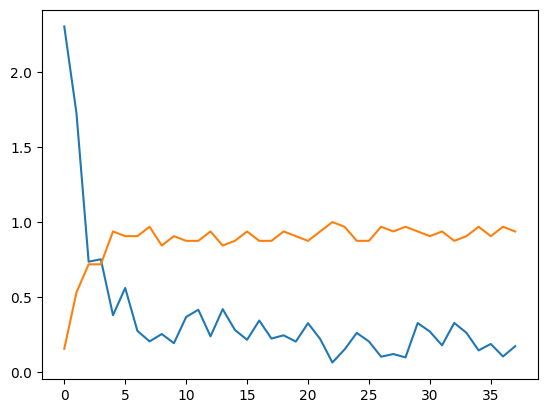

In [20]:
import matplotlib.pyplot as mp

mp.plot(losses)
mp.plot(accuracies)

### Testing

Probabilities: [[1.26853482e-01 1.59458412e-07 8.59649456e-04 1.58911193e-04
  1.12798598e-03 9.27510050e-03 8.57414644e-06 1.47115275e-01
  9.17331348e-04 7.13683531e-01]]
Prediction: [9]


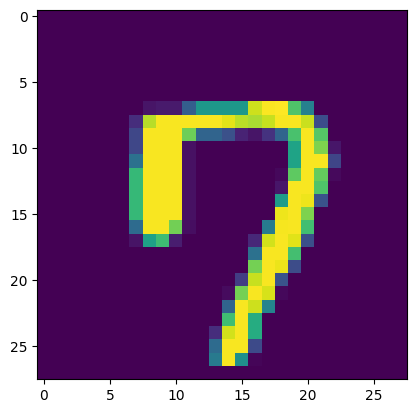

In [22]:
X = dataTest[1096]
y = dataTestLabels[1096]

output = myNeuralNet.forward(X)
print(f"Probabilities: {output}")

prediction = np.argmax(output, axis=1)
print(f"Prediction: {prediction}")

mp.imshow(X.reshape(28, 28))

Probabilities: [[2.83653272e-03 2.24805255e-06 1.51147205e-02 3.92532338e-05
  1.77981975e-02 1.46860693e-02 9.40766083e-01 2.81519415e-06
  7.85131784e-03 9.02762283e-04]]
Prediction: [6]


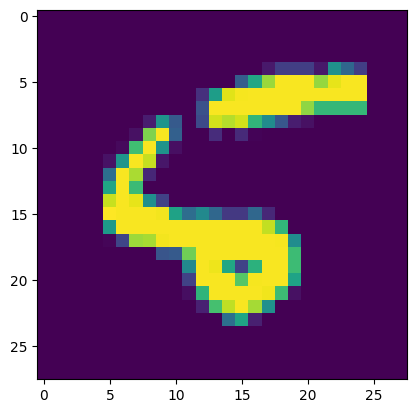

In [23]:
import matplotlib.pyplot as plt
for i in range(len(dataTest)):
    X = dataTest[i]
    y = dataTestLabels[i]

    output = myNeuralNet.forward(X)
    prediction = np.argmax(output, axis=1)
    if prediction[0] != y:
        print(f"Probabilities: {output}")
        print(f"Prediction: {prediction}")

        mp.imshow(X.reshape(28, 28))
        break

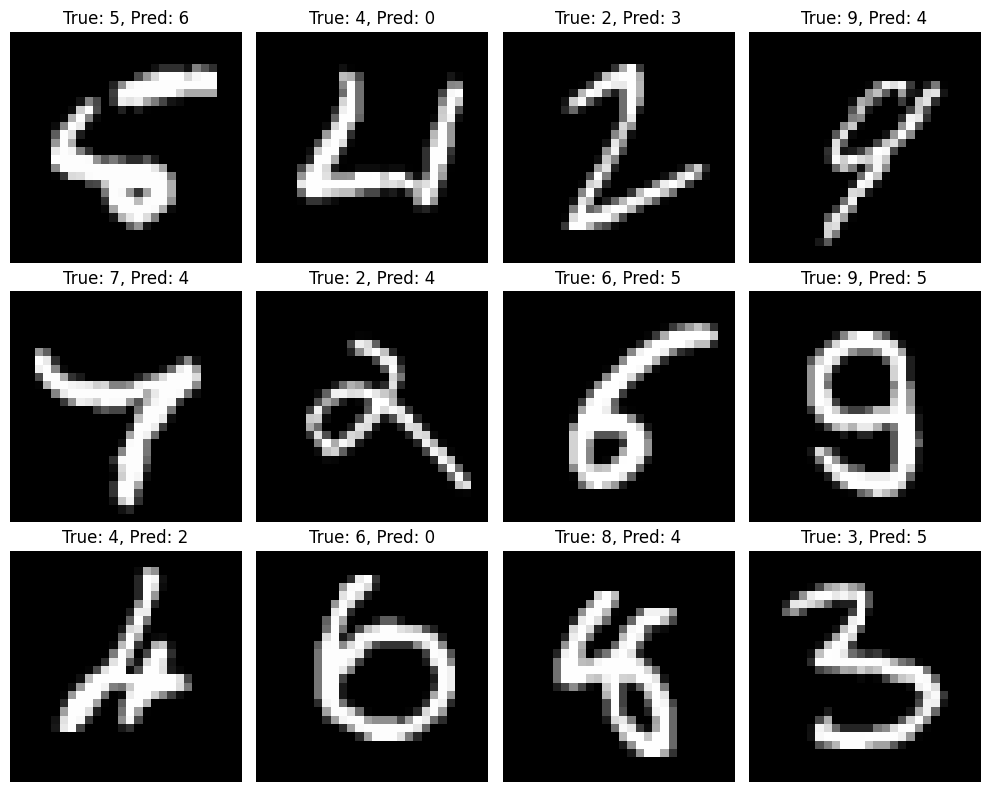

In [ ]:
incorrect_images = []
incorrect_labels = []
incorrect_predictions = []

for i in range(len(dataTest)):
    X = dataTest[i]
    y = dataTestLabels[i]

    output = myNeuralNet.forward(X)
    prediction = np.argmax(output, axis=1)
    if prediction[0] != y:
        incorrect_images.append(X)
        incorrect_labels.append(y)
        incorrect_predictions.append(prediction[0])

        if len(incorrect_images) == 12:
            break

fig, axes = plt.subplots(3, 4, figsize=(10, 8))
axes = axes.ravel()

for i in range(12):
    axes[i].imshow(incorrect_images[i].reshape(28, 28), cmap='gray')
    axes[i].set_title(f'True: {incorrect_labels[i]}, Pred: {incorrect_predictions[i]}')
    axes[i].axis('off')

plt.tight_layout()
plt.show()
